# Thiranex — Task 4: End-to-End Retail Analytics
**Project:** E-commerce sales analysis with customer, product and transaction tables  
**Author:** Pratyush  
**Data:** Fully synthetic, generated for educational practice. No real transactions or customers.

This notebook follows the *themes* of the supplied tutorial: relational joins, revenue, product/category and customer analytics, monthly trends, and charts. It is an original illustrative exercise, not a reproduction of the instructor’s dataset.

## 1. Import Python libraries and load the three input files
Upload `customers.csv`, `products.csv` and `transactions.csv` to Colab session storage before running. All files can also be read from a local directory.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
Path("charts").mkdir(exist_ok=True)

customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")
transactions = pd.read_csv("transactions.csv")
print("Customers:", customers.shape, "Products:", products.shape, "Transactions:", transactions.shape)
display(transactions.head())

Customers: (250, 3) Products: (20, 4) Transactions: (1800, 6)


,TransactionID,OrderDate,CustomerID,ProductID,Quantity,DiscountRate
0,T00001,2025-11-16,C0140,P015,3,0.05
1,T00002,2025-05-15,C0154,P016,2,0.00
2,T00003,2025-11-04,C0029,P019,2,0.00
3,T00004,2025-11-22,C0060,P013,1,0.00
4,T00005,2025-04-12,C0240,P006,3,0.00


## 2. Check data quality
Check null values, duplicates, IDs, quantities and discount ranges before analysis.

In [2]:
for name, frame in [("customers", customers), ("products",products), ("transactions",transactions)]:
    print(f"{name}: duplicates={frame.duplicated().sum()}")
    print(frame.isna().sum().to_string())
assert transactions.TransactionID.is_unique
assert products.ProductID.is_unique and customers.CustomerID.is_unique
assert transactions.Quantity.gt(0).all()
assert transactions.DiscountRate.between(0,1).all()

customers: duplicates=0
CustomerID    0
Region        0
Segment       0
products: duplicates=0
ProductID        0
ProductName      0
Category         0
UnitPrice_INR    0
transactions: duplicates=0
TransactionID    0
OrderDate        0
CustomerID       0
ProductID        0
Quantity         0
DiscountRate     0


## 3. Join customer, product, transaction data and calculate sales
Revenue = quantity × unit price × (1 − discount rate). Currency is INR. Validate joins so rows cannot accidentally multiply.

In [3]:
sales = transactions.merge(products, on="ProductID", how="left", validate="many_to_one").merge(customers,on="CustomerID",how="left",validate="many_to_one")
assert len(sales)==len(transactions) and sales[["UnitPrice_INR","Region"]].notna().all().all()
sales["OrderDate"]=pd.to_datetime(sales["OrderDate"],errors="raise")
sales["Revenue_INR"] = sales["Quantity"] * sales["UnitPrice_INR"] * (1-sales["DiscountRate"])
sales["Month"] = sales["OrderDate"].dt.to_period("M").astype(str)
sales.to_csv("retail_analysis_cleaned.csv",index=False)
display(sales.head())

,TransactionID,OrderDate,CustomerID,ProductID,Quantity,DiscountRate,ProductName,Category,UnitPrice_INR,Region,Segment,Revenue_INR,Month
0,T00001,2025-11-16,C0140,P015,3,0.05,Moisturizer,Beauty,680,North,Returning,1938.0,2025-11
1,T00002,2025-05-15,C0154,P016,2,0.00,Perfume,Beauty,1400,South,Returning,2800.0,2025-05
2,T00003,2025-11-04,C0029,P019,2,0.00,Bottle,Sports,420,South,Returning,840.0,2025-11
3,T00004,2025-11-22,C0060,P013,1,0.00,Shampoo,Beauty,320,East,New,320.0,2025-11
4,T00005,2025-04-12,C0240,P006,3,0.00,Jeans,Fashion,1600,South,New,4800.0,2025-04


## 4. Key retail KPIs

In [4]:
total_revenue=sales.Revenue_INR.sum(); orders=sales.TransactionID.nunique(); unique_customers=sales.CustomerID.nunique(); avg_order=total_revenue/orders
print(f"Total revenue: INR {total_revenue:,.2f}")
print(f"Orders: {orders:,}; Unique customers: {unique_customers:,}; Average order value: INR {avg_order:,.2f}")

Total revenue: INR 3,606,930.50
Orders: 1,800; Unique customers: 250; Average order value: INR 2,003.85


## 5. Monthly sales trends

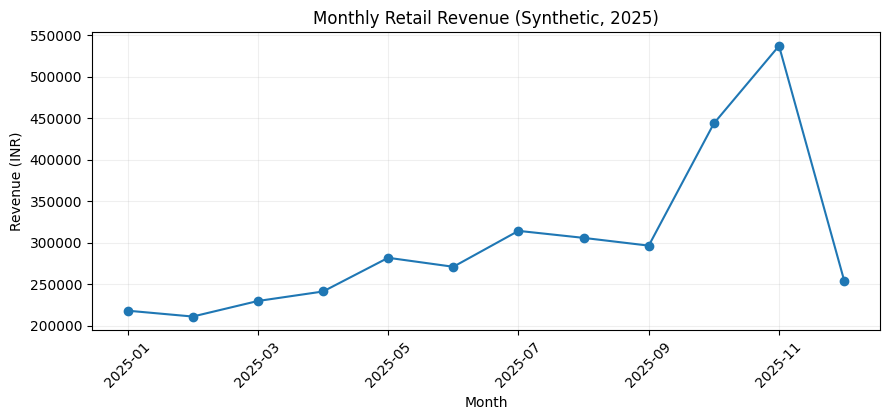

In [5]:
monthly=sales.groupby("Month")["Revenue_INR"].sum().sort_index()
fig,ax=plt.subplots(figsize=(9,4.3));monthly.plot(marker="o",ax=ax);ax.set(title="Monthly Retail Revenue (Synthetic, 2025)",ylabel="Revenue (INR)");ax.grid(alpha=.2);plt.xticks(rotation=45);plt.tight_layout();plt.savefig("charts/monthly_revenue.png");plt.show()

## 6. Category-wise and top-product performance

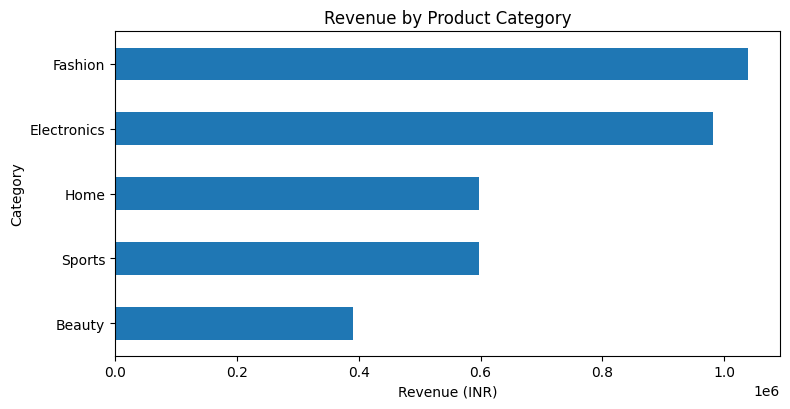

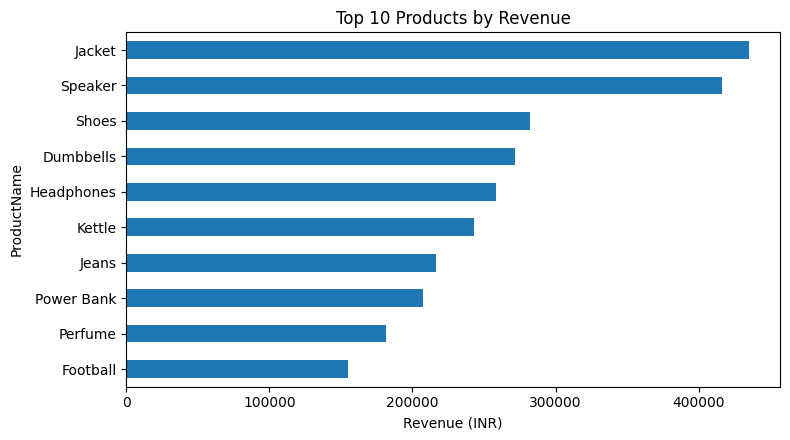

Category
Fashion        1039377.5
Electronics     982107.5
Home            597645.0
Sports          597609.5
Beauty          390191.0


In [6]:
category=sales.groupby("Category")["Revenue_INR"].sum().sort_values(ascending=False)
top_products=sales.groupby("ProductName")["Revenue_INR"].sum().sort_values(ascending=False).head(10)
fig,ax=plt.subplots(figsize=(8,4.2));category.sort_values().plot.barh(ax=ax);ax.set(title="Revenue by Product Category",xlabel="Revenue (INR)");plt.tight_layout();plt.savefig("charts/category_revenue.png");plt.show()
fig,ax=plt.subplots(figsize=(8,4.5));top_products.sort_values().plot.barh(ax=ax);ax.set(title="Top 10 Products by Revenue",xlabel="Revenue (INR)");plt.tight_layout();plt.savefig("charts/top_products.png");plt.show()
print(category.to_string())

## 7. Customer geographic and spending analysis

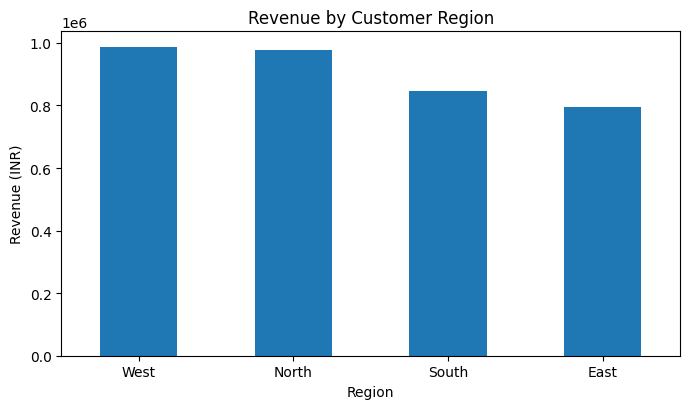

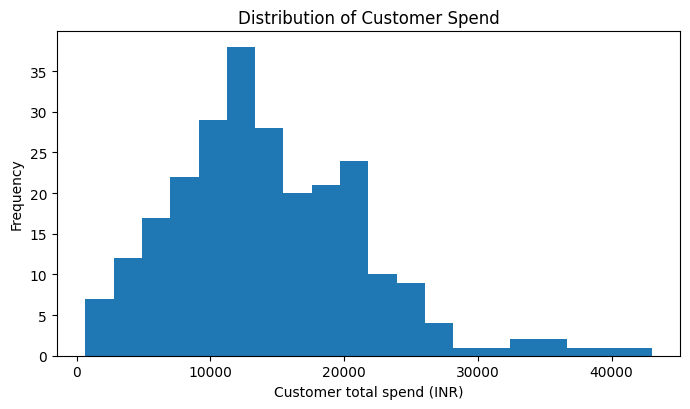

In [7]:
regional=sales.groupby("Region")["Revenue_INR"].sum().sort_values(ascending=False)
customer_spend=sales.groupby("CustomerID")["Revenue_INR"].sum()
fig,ax=plt.subplots(figsize=(7,4.2));regional.plot.bar(ax=ax);ax.set(title="Revenue by Customer Region",ylabel="Revenue (INR)");plt.xticks(rotation=0);plt.tight_layout();plt.savefig("charts/region_revenue.png");plt.show()
fig,ax=plt.subplots(figsize=(7,4.2));customer_spend.plot.hist(bins=20,ax=ax);ax.set(title="Distribution of Customer Spend",xlabel="Customer total spend (INR)");plt.tight_layout();plt.savefig("charts/customer_spending.png");plt.show()

## 8. Findings, limitations, and conclusion

In [8]:
print("Highest revenue month:", monthly.idxmax(), f"INR {monthly.max():,.2f}")
print("Top category:",category.index[0],f"INR {category.iloc[0]:,.2f}")
print("Top product:",top_products.index[0],f"INR {top_products.iloc[0]:,.2f}")
print("Highest revenue region:",regional.index[0])
print("Limitations: Synthetic dataset; simulated sales patterns do not demonstrate real market behavior or business causality.")

Highest revenue month: 2025-11 INR 537,454.50
Top category: Fashion INR 1,039,377.50
Top product: Jacket INR 434,980.00
Highest revenue region: West
Limitations: Synthetic dataset; simulated sales patterns do not demonstrate real market behavior or business causality.


**Conclusion:** This task demonstrates an end-to-end retail data workflow: inspect, join, calculate KPIs, analyze trends and categories, visualize, and present findings. Since inputs are synthetic, any insights are illustrative only. No machine-learning forecasting is claimed or required for this descriptive analysis.